In [20]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3


from datetime import date
import sys
sys.path.append("/storage/groups/ml01/workspace/jan.domke/Code/")
import scib_excerpts
import plot_ma

In [2]:
#Import color palette to get consistent colors across figures
import pickle  
with open('/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/colordict.pkl', 'rb') as f:
        colordict = pickle.load(f)

In [3]:
new_reds = plot_ma.shiftedColorMap(plot_ma.matplotlib.cm.Reds, midpoint=0.7, name='shifted')

In [4]:
today = date.today()
date = today.strftime("%d_%m_%Y")

In [5]:
nucleus_studies = ['Duong_lungMAP_unpubl', 'Eils_2020', 'Sun_2020']
nucleus_datasets = ['Duong_lungMAP_unpubl', 'Eils_2020', 'Sun_2020_batch1', 'Sun_2020_batch2', 'Sun_2020_batch3', 'Sun_2020_batch4']

In [6]:
# Import datasets with Milos differential abundance values for k = 50 
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_denovo_recalc_milo.h5ad")
denovo_ref = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_denovo_ref_milo.h5ad")
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_scarches_unlabeled_milo.h5ad")
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_scarches_labeled_milo.h5ad")

In [7]:
# Import milo logFC values calculated with k=150
denovo_recalc_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_denovo_recalc_logFC.h5ad")
denovo_ref_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_denovo_ref_logFC.h5ad")
scarches_unlabeled_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_scarches_unlabeled_logFC.h5ad")
scarches_labeled_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_scarches_labeled_logFC.h5ad")

In [8]:
scarches_labeled_logFC_avg = pd.read_pickle("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/New_higher_k/nucleus_scarches_labeled_logFC_II.h5ad")

In [9]:
# Update milo logFC values with new ones calculated with k=150
denovo_recalc.obs.logFC_avg = denovo_recalc_logFC_avg
denovo_ref.obs.logFC_avg = denovo_ref_logFC_avg
scarches_unlabeled.obs.logFC_avg = scarches_unlabeled_logFC_avg
scarches_labeled.obs.logFC_avg = scarches_labeled_logFC_avg

In [10]:
# Show how many cells,datasets,studies are included in reference and query
ncells = denovo_recalc.obs.groupby("origin").size()
ndata = denovo_recalc.obs.groupby("origin").dataset.nunique()
nstudy = denovo_recalc.obs.groupby("origin").study.nunique()

names = ["cells", "datasets", "studies"]
counts_nucleus = pd.concat([ncells,ndata,nstudy],axis=1)
counts_nucleus = counts_nucleus.rename({0:"cells"},axis=1)
counts_nucleus

,cells,dataset,study
origin,,,
query,140182,6,3
reference,584884,14,11


In [11]:
# get original scanvi_labels for scarches_unlabeld back
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("string")
scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label_original"] = scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label"].astype(str)
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("category")

In [12]:
#calculate differential embedding score
scarches_unlabeled.obs["diff_denovo_recalc"] = abs(scarches_unlabeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
scarches_unlabeled.obs["diff_denovo_ref"] = abs(scarches_unlabeled.obs.logFC_avg - denovo_ref.obs.logFC_avg)
scarches_unlabeled.obs["diff_scArches_labeled"] = abs(scarches_unlabeled.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
scarches_labeled.obs["diff_denovo_recalc"] = abs(scarches_labeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
scarches_labeled.obs["diff_denovo_ref"] = abs(scarches_labeled.obs.logFC_avg - denovo_ref.obs.logFC_avg)
scarches_labeled.obs["diff_scArches_unlabeled"] = abs(scarches_labeled.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_ref.obs["diff_denovo_recalc"] = abs(denovo_ref.obs.logFC_avg - denovo_recalc.obs.logFC_avg)
denovo_ref.obs["diff_scArches_labeled"] = abs(denovo_ref.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
denovo_ref.obs["diff_scArches_unlabeled"] = abs(denovo_ref.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_recalc.obs["diff_scArches_unlabeled"] = abs(denovo_recalc.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg)
denovo_recalc.obs["diff_scArches_labeled"] = abs(denovo_recalc.obs.logFC_avg - scarches_labeled.obs.logFC_avg)
denovo_recalc.obs["diff_denovo_ref"] = abs(denovo_recalc.obs.logFC_avg - denovo_ref.obs.logFC_avg)

In [13]:
del scarches_unlabeled.uns['scanvi_label_colors']
del scarches_labeled.uns['scanvi_label_colors']
del denovo_recalc.uns['scanvi_label_colors']
del denovo_ref.uns['scanvi_label_colors']

In [14]:
scarches_unlabeled_plot = sc.pp.subsample(scarches_unlabeled, fraction=1., copy=True)
scarches_labeled_plot = sc.pp.subsample(scarches_labeled, fraction=1., copy=True)
denovo_ref_plot = sc.pp.subsample(denovo_ref, fraction=1., copy=True)
denovo_recalc_plot = sc.pp.subsample(denovo_recalc, fraction=1., copy=True)

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


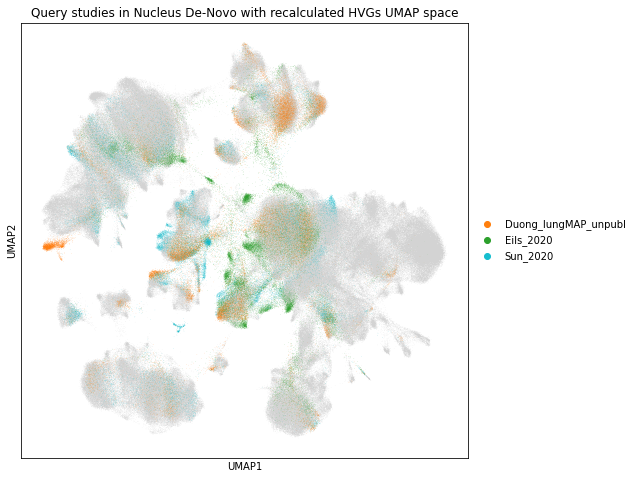

In [13]:
sc.pl.umap(denovo_recalc_plot, color="study",  size = 0.5, sort_order = False, groups = nucleus_studies, palette ="tab10",
          title = "Query studies in Nucleus De-Novo with recalculated HVGs UMAP space", na_in_legend=False
          #save = f"_nucleus_denovo_recalc_origin_{date}.png"
          )

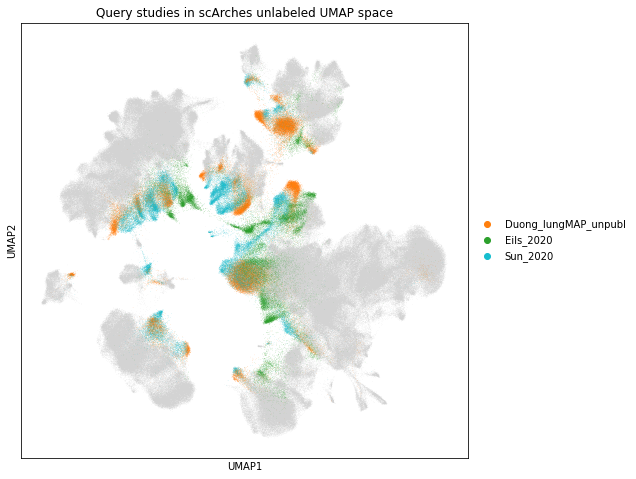

In [15]:
sc.pl.umap(scarches_unlabeled_plot, color="study",  size = 0.5, sort_order = False, groups = nucleus_studies, palette = "tab10",
          title = "Query studies in scArches unlabeled UMAP space", na_in_legend=False
          #save = f"_nucleus_denovo_recalc_origin_{date}.png"
          )

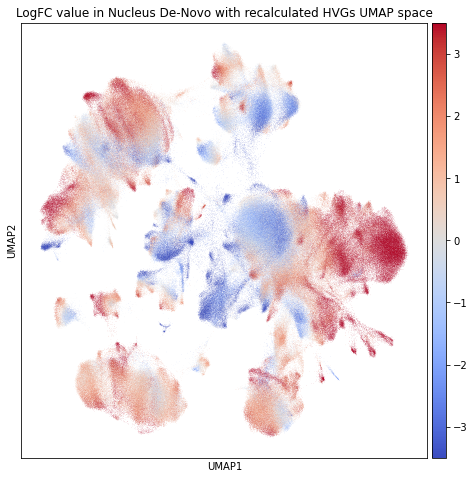

In [17]:
sc.pl.umap(denovo_recalc_plot, color="logFC_avg",color_map="coolwarm",vmin=-3.5,vmax=3.5, size = 0.3, sort_order = False,
          title = "LogFC value in Nucleus De-Novo with recalculated HVGs UMAP space",
          save = f"_nucleus_denovo_recalc_logFC_{date}.png")

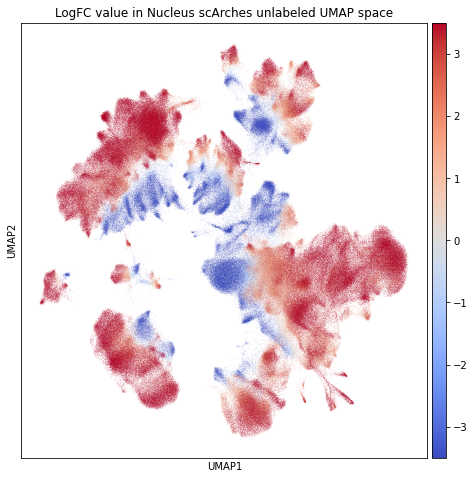

In [19]:
sc.pl.umap(scarches_unlabeled_plot, color="logFC_avg", color_map = "coolwarm", vmin = -3.5, vmax = 3.5, size = 0.3, sort_order = False,
          title = "LogFC value in Nucleus scArches unlabeled UMAP space",
          save = f"_nucleus_scarches_unlabeled_logFC_{date}.png")

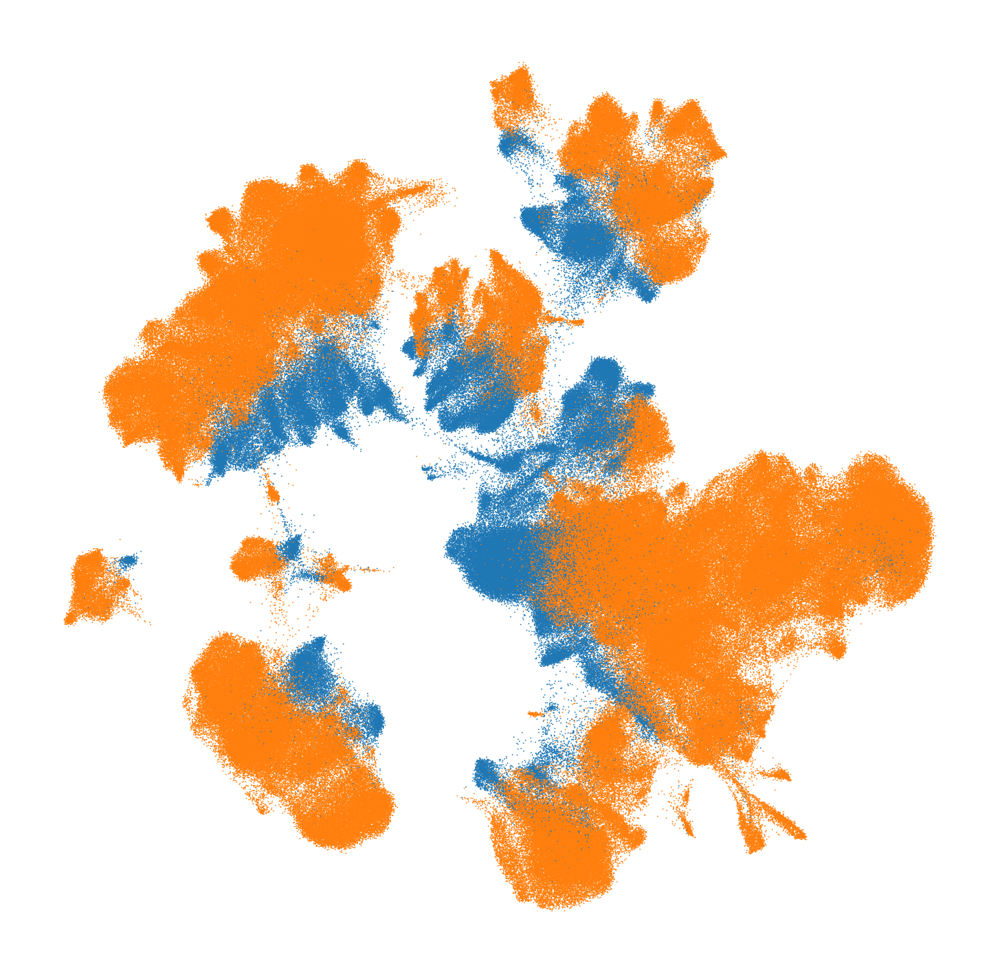

In [19]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_plot, color="origin", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False, legend_loc=None,
                   title="")
    #plt.show()
    plt.savefig("figures/scArches_nucleus_extension_origin.png")

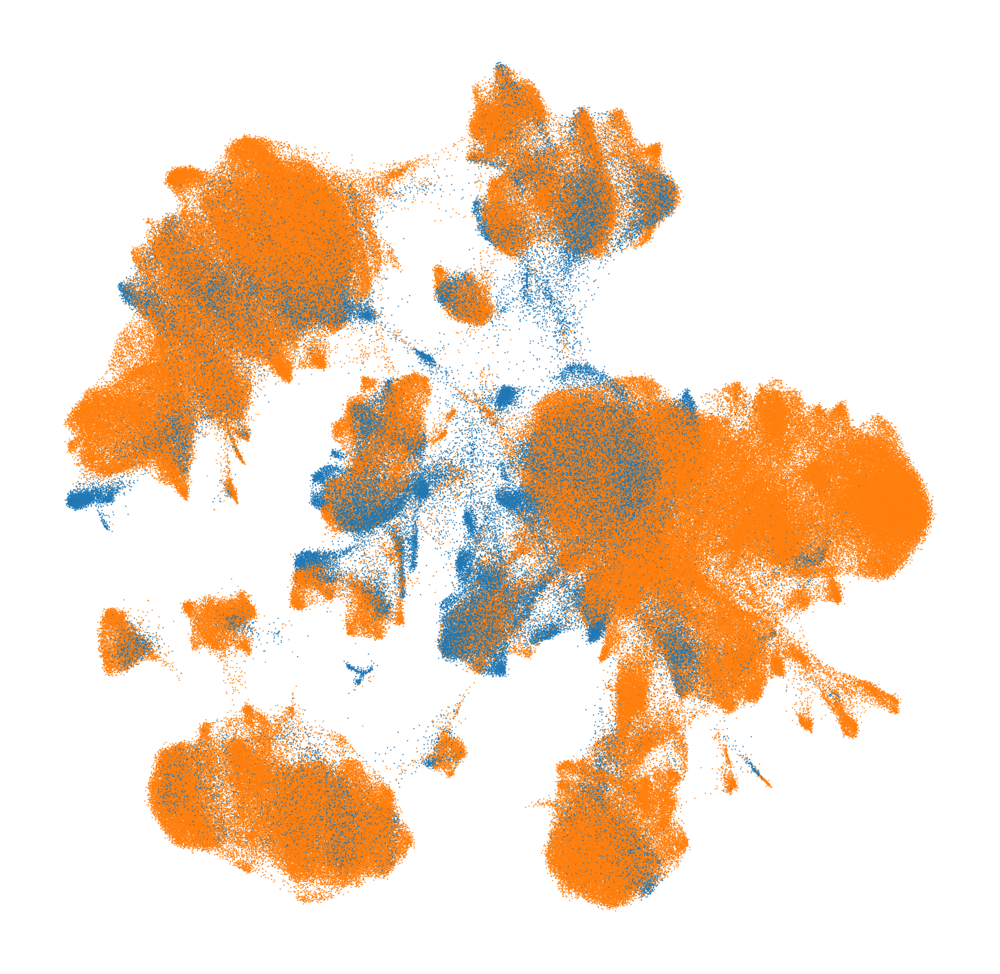

In [18]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_plot, color="origin", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False, legend_loc=None,
                   title="")
    plt.savefig("figures/scANVI_nucleus_extension_origin.png")

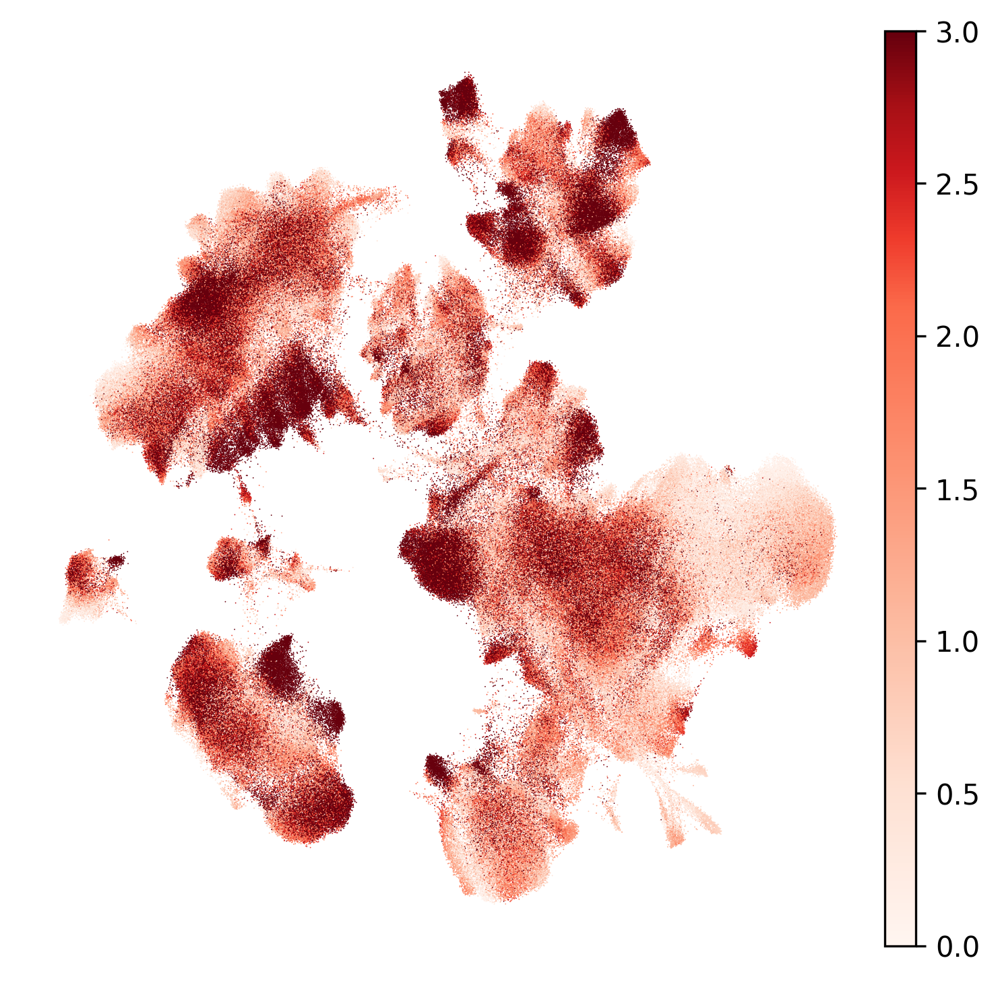

In [20]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_plot, color="diff_denovo_recalc", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    #plt.show()
    plt.savefig("figures/scArches_nucleus_extension_milo.png")

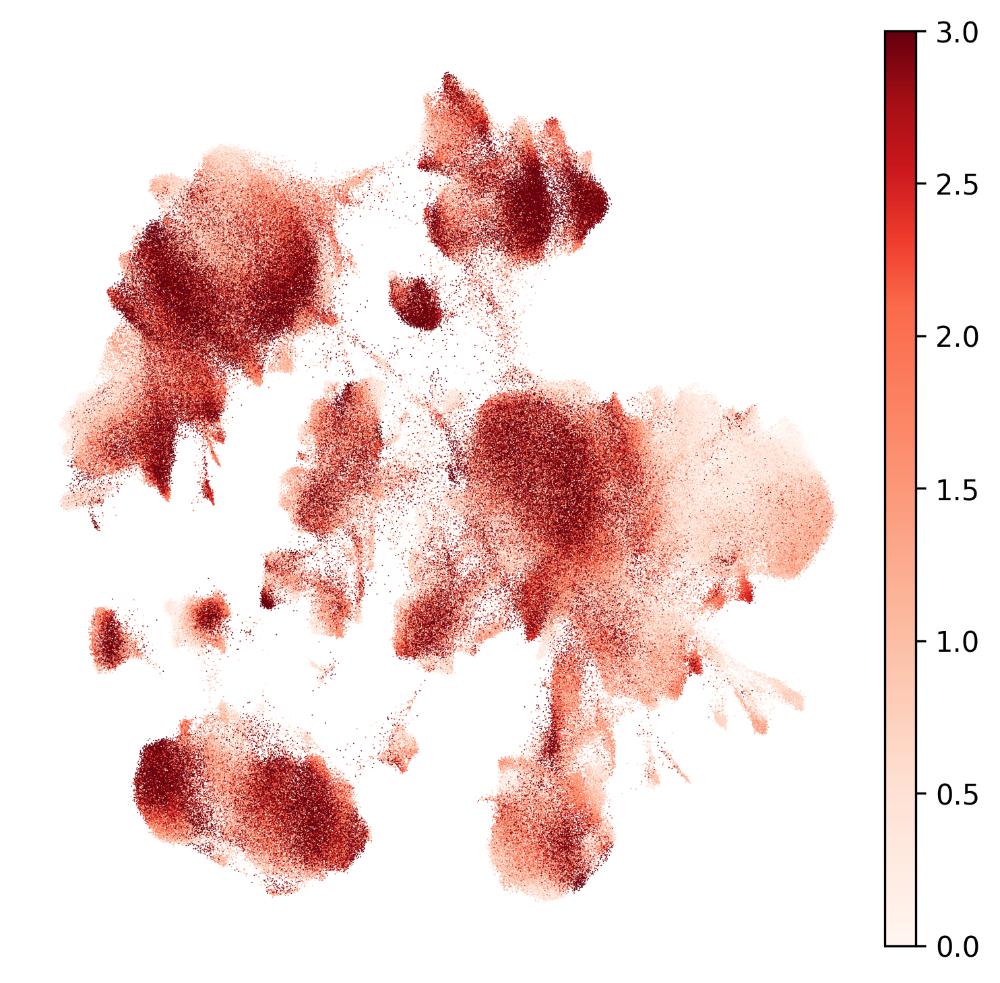

In [21]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_plot, color="diff_scArches_unlabeled", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    plt.savefig("figures/scANVI_nucleus_extension_milo.png")

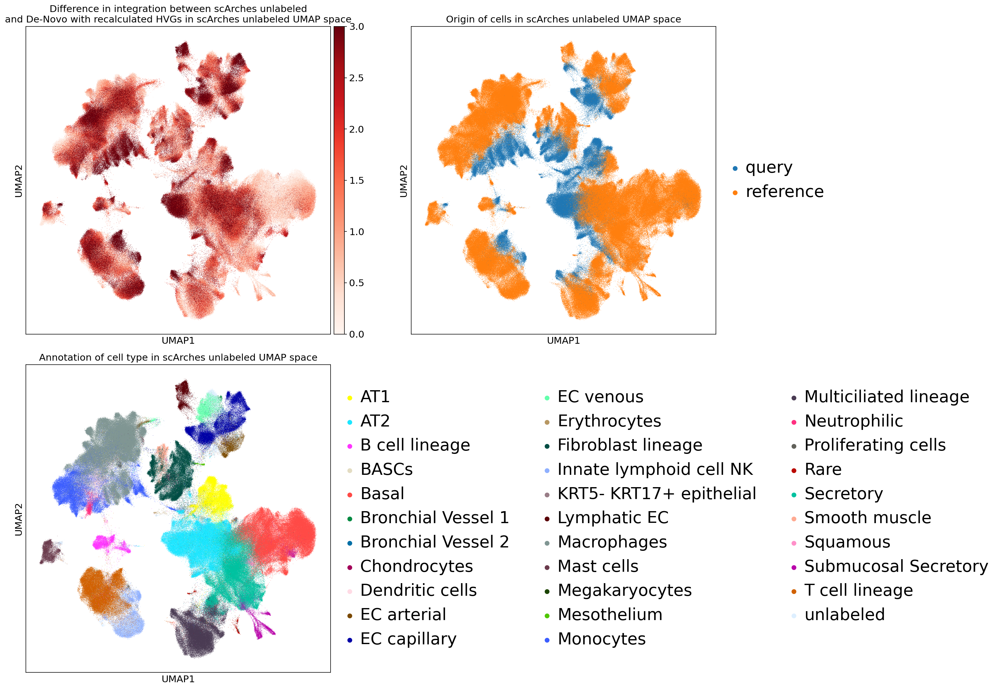

In [24]:
sc.pl.umap(scarches_unlabeled_plot, color = ["diff_denovo_recalc", "origin", "scanvi_label_original"], 
          vmin = 0, vmax = 3, cmap = "Reds", palette = colordict, size = 1, sort_order = False, wspace=0.15, hspace = 0.1, ncols = 2,
           legend_fontsize = 24,
          #save = f"_nucleus_scarches_unlabeled_{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in scArches unlabeled UMAP space",
                  "Origin of cells in scArches unlabeled UMAP space",
                  "Annotation of cell type in scArches unlabeled UMAP space"])

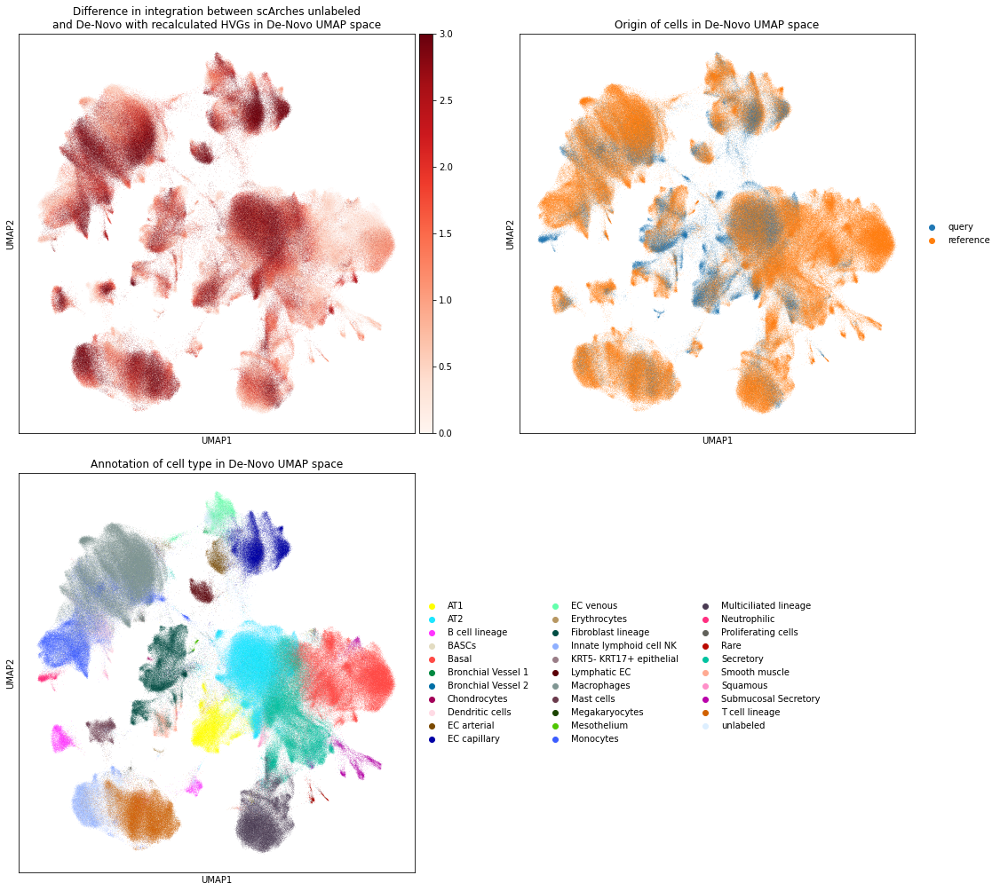

In [23]:
sc.pl.umap(denovo_recalc_plot, color = ["diff_scArches_unlabeled", "origin", "scanvi_label"], 
          vmin = 0, vmax = 3, cmap = "Reds", palette = colordict, size = 0.5, sort_order = False, wspace=0.15, hspace = 0.1, ncols = 2,
          save= f"_nucleus_denovo_recalc_{date}.png",
          title = ["Difference in integration between scArches unlabeled\nand De-Novo with recalculated HVGs in De-Novo UMAP space",
                  "Origin of cells in De-Novo UMAP space",
                  "Annotation of cell type in De-Novo UMAP space"])

### 1.1 Compare with Control Group (scANVI with reference HVGs)

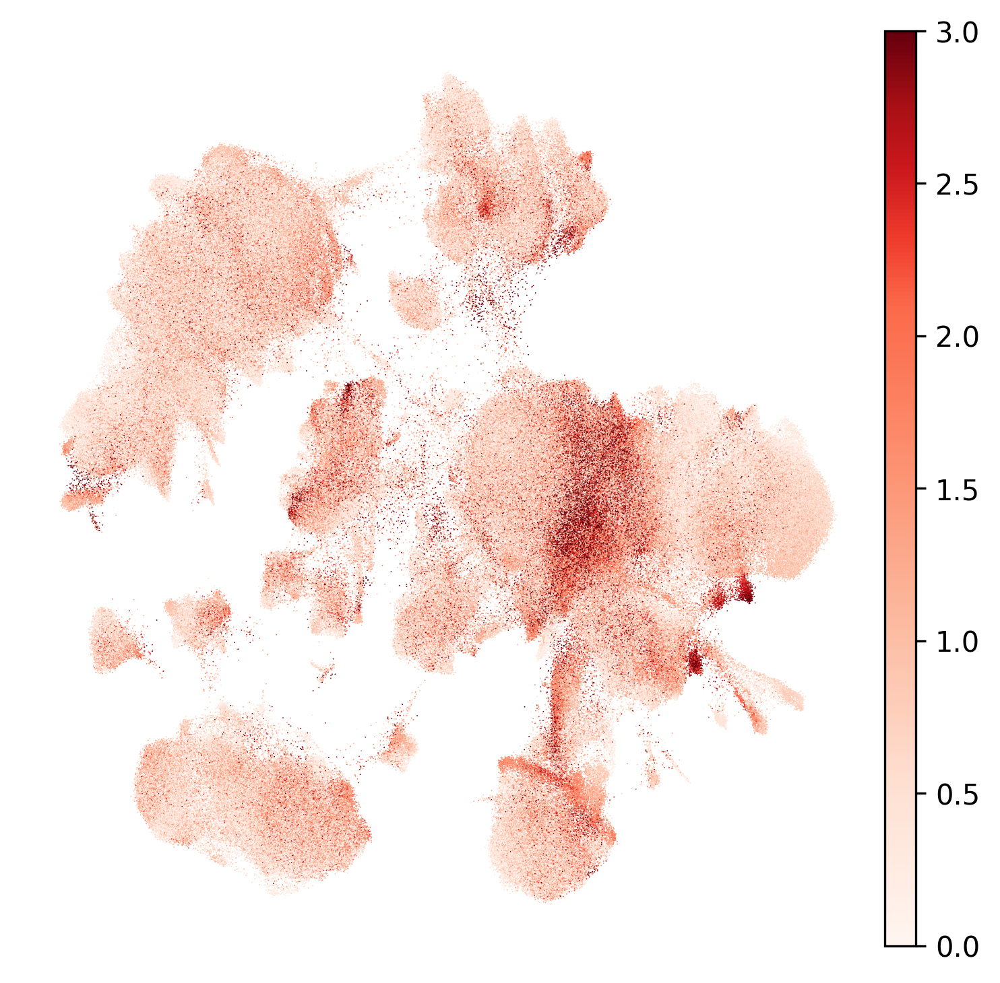

In [17]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_plot, color="diff_denovo_ref", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    #plt.show()
    plt.savefig("figures/Nucleus_control_denovo_recalc_denovo_ref.png")

### 1.2 Compare with Control Group (scArches labeled)

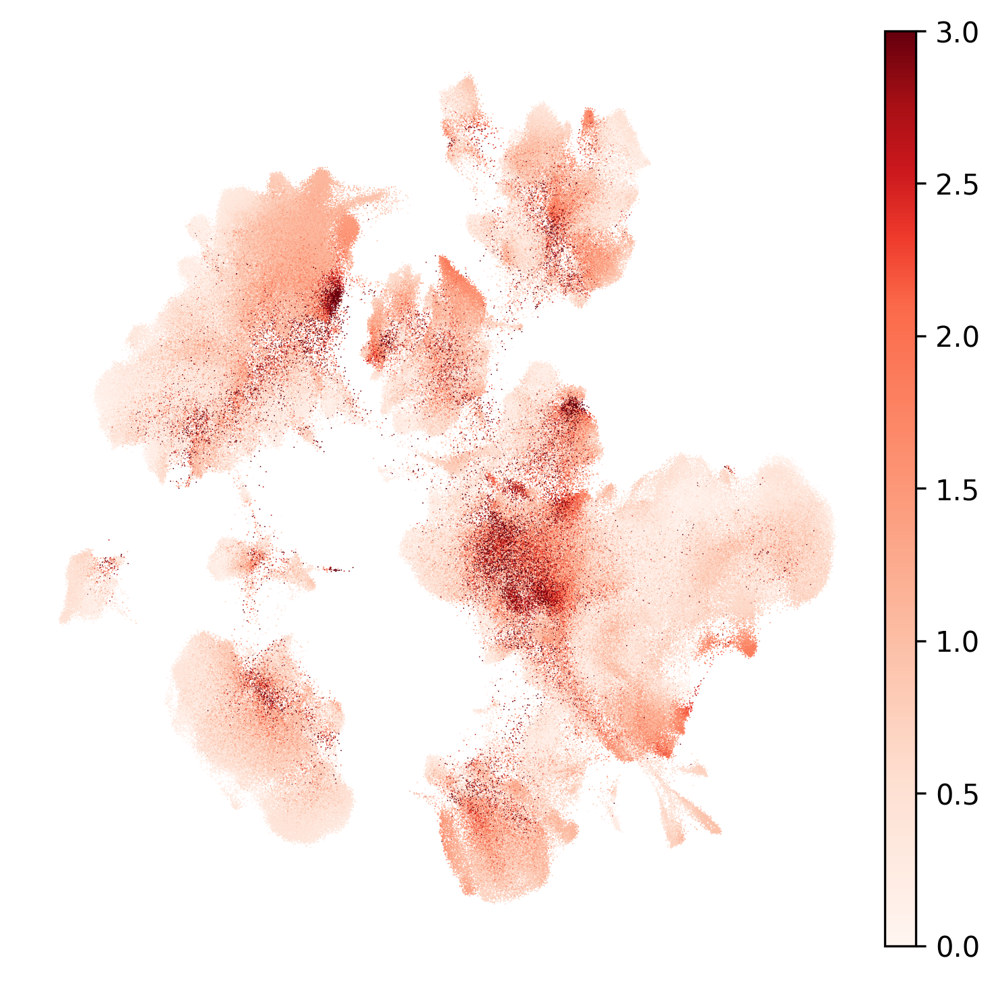

In [30]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_plot, color="diff_scArches_labeled", palette = colordict, size = 0.75, sort_order = False, show=False, frameon=False,
                    vmin=0,vmax=3, cmap=new_reds,
                   title="")
    #plt.show()
    plt.savefig("figures/nucleus_control_scarches_unlabeled_scarches_labeled.png")

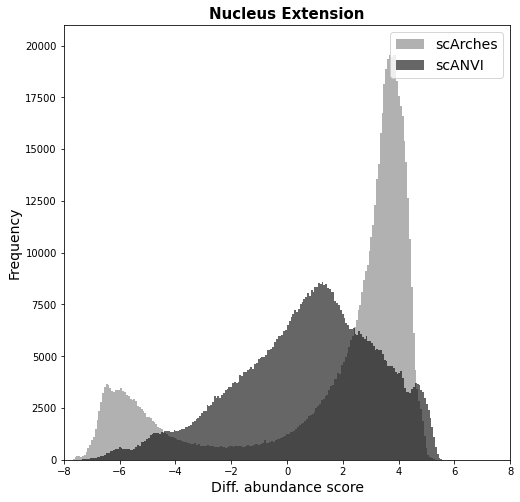

In [22]:
plt.hist(scarches_unlabeled.obs.logFC_avg, bins=200, color = "darkgrey",alpha=0.9, label="scArches")
plt.hist(denovo_recalc.obs.logFC_avg, bins=200, color = "black",alpha=0.6, label="scANVI")
plt.ylim(0,21000)
plt.xlim(-8,8)
plt.title("Nucleus Extension",size=15,fontweight="bold")
plt.xlabel("Diff. abundance score",size=14)
plt.ylabel("Frequency",size=14)
plt.legend(loc='upper right',prop={'size': 14})
plt.grid(False)
plt.savefig("figures/nucleus_extension_DA_score_distr.png")

# Violin Plots 

In [16]:
# Sort labels by median of difference of logFC value
labels_sorted = list(scarches_unlabeled.obs.groupby("scanvi_label_original")["diff_denovo_recalc"].median().sort_values().index)

In [17]:
sort_by = [labels_sorted.index(x) for x in sorted(labels_sorted)]

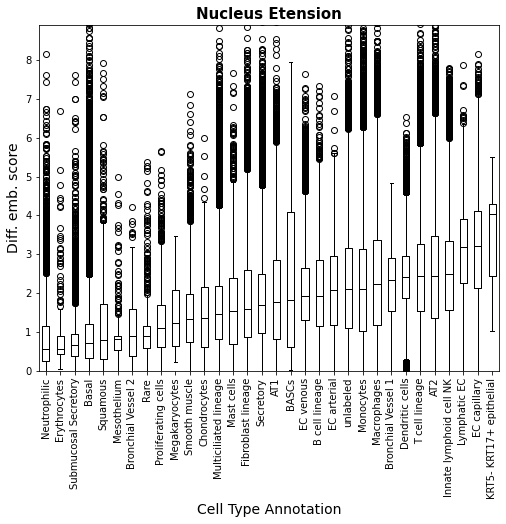

In [18]:
scarches_unlabeled.obs.boxplot(column='diff_denovo_recalc',by='scanvi_label_original', positions=sort_by,
                              boxprops=dict(color="0"), medianprops=dict(color="0"), whiskerprops=dict(color="0"))
plt.xticks(rotation=90)
plt.title("Nucleus Etension",fontweight="bold",size=15)
plt.xlabel("Cell Type Annotation",size=14)
plt.ylabel("Diff. emb. score",size=14)
plt.ylim(0,8.9)
plt.grid(False)
plt.suptitle('')
plt.subplots_adjust(bottom=0.3)
plt.savefig(f"figures/nucleus_boxplot_scanvi_label_{date}.jpg")

In [59]:
sc.logging.print_versions()


-----
anndata     0.7.5
scanpy      1.8.2
sinfo       0.3.1
-----
PIL                 8.1.0
anndata             0.7.5
anyio               NA
attr                20.3.0
babel               2.9.0
backcall            0.2.0
brotli              1.0.9
certifi             2020.12.05
cffi                1.14.4
chardet             4.0.0
cloudpickle         1.6.0
constants           NA
cycler              0.10.0
cython_runtime      NA
dask                2020.12.0
dateutil            2.8.1
decorator           4.4.2
future_fstrings     NA
google              NA
h5py                2.10.0
highs_wrapper       NA
idna                2.10
igraph              0.8.3
ipykernel           5.4.3
ipython_genutils    0.2.0
ipywidgets          7.6.3
jedi                0.18.0
jinja2              2.11.2
joblib              1.0.0
json5               NA
jsonschema          3.2.0
jupyter_server      1.2.1
jupyterlab_server   2.1.2
kiwisolver          1.3.1
leidenalg           0.8.3
llvmlite            0.35.0
louv